<a href="https://colab.research.google.com/github/ArseniyFaryna/Intelligent_analisis_labs/blob/main/%D0%9B%D0%A05_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_%D1%81%D1%82%D1%83%D0%B4%D0%B5%D0%BD%D1%82%D1%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [40]:
STUDENT_NAME = 'Фарина Арсеній Петрович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 18      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 18: Суми, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [41]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [42]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [43]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_суми


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [44]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 1, відповідають 1 ['162.55.144.139']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [45]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    # ----- ВАШ КОД: живий запит -----
    # 1) запам'ятайте cache_bytes() і час ДО виклику getter()
    # 2) викличте getter(), проженіть результат через clean(), збережіть у path
    # 3) запишіть у COST[name] спосіб 'живий запит', записів, передано_МБ,
    #    файл_МБ і секунд

    bytes_before = cache_bytes()
    t0 = time.time()

    raw = getter()
    g = clean(raw)

    tmp = path + '.tmp'
    g.to_parquet(tmp)
    os.replace(tmp, path)

    secs = time.time() - t0
    sent_mb = (cache_bytes() - bytes_before) / 1e6

    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round(sent_mb, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(secs, 3)}
    return g


    raise NotImplementedError('напишіть гілку живого запиту')

In [46]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 106.4 км²


In [47]:
def with_retry(getter, tries=5, wait=10):
    for i in range(tries):
        try:
            return getter()
        except ox._errors.ResponseStatusCodeError as e:
            if i == tries - 1:
                raise
            print(f'Сервер зайнятий, спроба {i + 2} через {wait} с')
            time.sleep(wait)
            wait *= 2

heritage = fetch('heritage', lambda: with_retry(lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK})))
stations = fetch('stations', lambda: with_retry(lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']})))
amenities = fetch('amenities', lambda: with_retry(lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']})))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 14456 | ребер 42852


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [48]:
import pandas as pd

tbl = pd.DataFrame(COST).T

live = tbl[tbl['спосіб'] == 'живий запит']
snap = tbl[tbl['спосіб'] == 'знімок']

speedup = live['секунд'].sum() / snap['секунд'].sum()

saved_mb = live['передано_МБ'].sum()

print(f'Знімок швидший у {speedup:.0f} разів')
print(f'Не передано мережею: {saved_mb:.3f} МБ')

display(pd.DataFrame(COST).T)

Знімок швидший у 0 разів
Не передано мережею: 0.000 МБ


,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.025,0.07
heritage,знімок,195,0.0,0.079,0.079
stations,знімок,10,0.0,0.031,0.062
amenities,знімок,252,0.0,0.065,0.07
мережа walk,знімок,57308,0.0,2.771,0.28


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [49]:
# ----- ВАШ КОД -----
HIST_OK = {'castle', 'church', 'monument', 'memorial', 'ruins', 'tower', 'yes'}
TOUR_OK = {'museum', 'gallery', 'attraction', 'artwork', 'viewpoint'}

has_hist = heritage['historic'].isin(HIST_OK) if 'historic' in heritage else False
has_tour = heritage['tourism'].isin(TOUR_OK) if 'tourism' in heritage else False

mask = has_hist | has_tour

has_name = heritage['name'].notna() & (heritage['name'].astype(str).str.strip() != '') \
    if 'name' in heritage else False

cand = heritage[mask & has_name].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))
print('відкинуто за тегами    :', len(heritage) - int(mask.sum()))
print('відкинуто без name     :', int(mask.sum()) - len(cand))

усього у шарі heritage : 195
підходять за тегами    : 172
з них мають name       : 124
відкинуто за тегами    : 23
відкинуто без name     : 48


In [50]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial    47
ruins        4
monument     3
yes          2
castle       1
manor        1
tomb         1

=== tourism ===
tourism
artwork       41
museum        12
attraction    10
gallery        5

типи геометрії: {'Point': 114, 'Polygon': 10}


У шарі heritage було 196 об'єктів. За тегами підійшли 173 (historic або tourism зі списку пам'яток), а 23 відкинуто, бо їхні теги не належать до категорії пам'яток. Серед 173 кандидатів назву мають 125, а 48 відкинуто як такі, що не мають name. Після обох фільтрів залишилося 125 кандидатів.

Частка відкинутих за тегами - 23 з 196, тобто приблизно 12%. Частка відкинутих без назви - 48 з 173, тобто приблизно 28%. Саме фільтр за назвою відсіює більше, тому на практиці він важливіший для якості набору.

> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

Після відбору за тегами та назвою залишилося 125 кандидатів, що перевищує поріг у 30 об'єктів, тому розширення переліку тегів не знадобилося

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [51]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)
def col(df, c):
    return df[c].notna() & (df[c].astype(str).str.strip() != '') if c in df else pd.Series(False, index=df.index)

cand['wiki'] = (col(cand, 'wikidata') | col(cand, 'wikipedia')).astype(int)

name_cols = [c for c in cand.columns if c.startswith('name:')]
cand['n_lang'] = cand[name_cols].apply(
    lambda r: sum(pd.notna(v) and str(v).strip() != '' for v in r), axis=1
) if name_cols else 0

cand['visit'] = cand['tourism'].isin(['museum', 'gallery', 'attraction', 'artwork', 'viewpoint']).astype(int) \
    if 'tourism' in cand else 0

cand['hist_typed'] = (col(cand, 'historic') & (cand['historic'].astype(str) != 'yes')).astype(int) \
    if 'historic' in cand else 0

r_wiki  = cand['wiki'].rank(pct=True)
r_lang  = cand['n_lang'].rank(pct=True)
r_area  = cand['area_m2'].rank(pct=True)
r_visit = cand['visit'].rank(pct=True)
r_hist  = cand['hist_typed'].rank(pct=True)

W = {'wiki': 0.35, 'lang': 0.25, 'visit': 0.20, 'hist': 0.10, 'area': 0.10}

cand['score'] = (W['wiki']*r_wiki + W['lang']*r_lang + W['visit']*r_visit
                 + W['hist']*r_hist + W['area']*r_area)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('ваги         :', W)
print(cand.sort_values('score', ascending=False)[['name', 'score', 'wiki', 'n_lang']].head(10).to_string(index=False))

кандидатів   : 124
мають wiki   : 20
ваги         : {'wiki': 0.35, 'lang': 0.25, 'visit': 0.2, 'hist': 0.1, 'area': 0.1}
                                            name    score  wiki  n_lang
             Сумський обласний краєзнавчий музей 0.824798     1       2
Сумський обласний художній музей ім. Н.Онацького 0.823992     1       2
             Садиба графині Параскеви Штеричевої 0.822782     1       2
                                        Альтанка 0.821573     1       2
                             Садиба Линтварьових 0.773185     1       2
        Пам'ятник Івану Герасимовичу Харитоненку 0.722782     1       2
                                  Кожедубу І. М. 0.722782     1       2
                         Пам'ятник Т.Г. Шевченку 0.722782     1       2
                     Садиба Суханових-Сумовських 0.717944     1       1
         Меморіальний будинок-музей А. П. Чехова 0.717540     1       1


Wiki — 0.35. Найсильніший сигнал: стаття у Wikipedia або запис у Wikidata означає, що сторонні редактори визнали об'єкт вартим опису.

Мови — 0.25. Переклади назви говорять, що об'єкт цікавий людям з інших країн, тобто туристам, а не лише місцевим.

Visit — 0.20. Музеї, галереї та інші заклади, призначені для відвідування, прямо відповідають тому, що шукає турист.

Hist — 0.10. Історичний тип об'єкта вказує на природу пам'ятки, але багато історичних об'єктів без туристичного значення, тому вага менша.

Площа — 0.10. Найслабший сигнал: великим буває склад чи промзона. Вага низька, щоб не перевищувати реальну цінність.

### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [52]:
N_SMALL, N_LARGE = 10, 30

top_score = cand.nlargest(N_LARGE, 'score')
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2')

overlap = len(set(top10.index) & set(top_naive.index))

print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({
    'за вашим критерієм': list(top10['name']),
    'за площею': list(top_naive['name']),
}))

перетин: 5 з 10


,за вашим критерієм,за площею
0,Сумський обласний краєзнавчий музей,Руїни заводу КРЗ
1,Сумський обласний художній музей ім. Н.Онацького,Садиба Линтваревих
2,Садиба графині Параскеви Штеричевої,Сумський обласний краєзнавчий музей
3,Альтанка,Сумський обласний художній музей ім. Н.Онацького
4,Садиба Линтварьових,Садиба Линтварьових
5,Пам'ятник Івану Герасимовичу Харитоненку,Меморіальний будинок-музей А. П. Чехова
6,Пам'ятник Т.Г. Шевченку,Альтанка
7,Кожедубу І. М.,Піраміда
8,Садиба Суханових-Сумовських,Бурлюміда
9,Меморіальний будинок-музей А. П. Чехова,Пам'ятник рафінаду


Для відбору «найкращих» пам'яток Сум було побудовано два рейтинги з однакових даних. Перший, основний, поєднує чотири сигнали: наявність Wikipedia або Wikidata (вага 0,35), кількість перекладів назви (0,25), призначення для відвідування (0,20) і тип історичного об'єкта (0,10), а також площу як найслабший сигнал (0,10). Кожен сигнал переведено у шкалу від 0 до 1 через перцентильний ранг, щоб різнорідні величини були порівнянні. Другий, контрольний, ранжує кандидатів лише за площею будівлі. З 10 найкращих за основним рейтингом і 10 найбільших за площею збіглися п'ять: два музеї, садиба Линтварьових, меморіальний будинок-музей Чехова та альтанка. Ще п'ять об'єктів потрапили лише в основний список (переважно пам'ятники й садиби з визнанням у Wikipedia чи Wikidata, але малої площі), а інші п'ять лише за площею (зокрема руїни заводу, пам'ятник рафінаду та інші великі або незвичні полігони, які, ймовірно, не є туристичними об'єктами).

Отже, слово «найкращі» залежить від критерію. Площа вимірює розмір, а не цінність для відвідувача: вона винесла в топ промислові руїни, які не мають туристичного значення. Обраний нами критерій свідомо надає перевагу визнанню й придатності для відвідування, тому його результат відповідає задачі краще, але це вибір, а не об'єктивна істина. Розбіжність у п'ять із десяти показує, що вибір критерію змінює список майже вдвічі, тому в роботі він має бути обґрунтований і зазначений прямо.

### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [53]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

pairs = close_pairs(top_score, limit_m=60)

print('знайдено пар до 60 м:', len(pairs))
for i, j, d in pairs:
    a, b = top_score.iloc[i], top_score.iloc[j]
    print(f"{d:6.1f} м | {a['name']}  <->  {b['name']}")

знайдено пар до 60 м: 5
  19.3 м | Садиба Линтварьових  <->  Садиба Линтваревих
  46.4 м | Садиба Линтварьових  <->  Меморіальний будинок-музей А. П. Чехова
  48.0 м | Садиба Суханових-Сумовських  <->  Музей грошей
  52.1 м | Пам'ятник Івану Герасимовичу Харитоненку  <->  Партизанський рейд
  59.7 м | Сумський обласний краєзнавчий музей  <->  Альтанка


Серед 30 найкращих за рейтингом знайдено п'ять пар об'єктів ближче 60 м одна до одної. Одну пару, садибу Линтварьових і садибу Линтваревих (19 м), злито як дубль з різним написанням назви; решту чотири залишено, бо це різні об'єкти з різним призначенням, наприклад садиба і музей. Злиття змінює склад топу, тому після нього рейтинг, топ-10 і перетин із площею треба перерахувати. Перетин 5 з 10 може змінитися, оскільки запис Линтваревих входить до топу за площею.

---
## 4. Старт: вокзал, і прив'язка точок до графа

In [54]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 10
                      name  railway       building
0                     Баси  station           <NA>
1                    Олдиш     halt           <NA>
2             Суми-Товарна  station           <NA>
3                    52 км     halt           <NA>
4               з.п. 59 км     halt           <NA>
5                     Суми  station           <NA>
6        Приміський вокзал     <NA>  train_station
7  Залізничний вокзал Суми     <NA>  train_station
8                     <NA>     <NA>  train_station
9              Вокзал Баси     <NA>  train_station


In [55]:
# ----- ВАШ КОД -----
mask_main = (stations['name'] == 'Суми') & (stations['railway'] == 'station')
station = stations[mask_main].head(1)

if station.empty:
    station = stations[stations['building'] == 'train_station'].head(1)

print('старт:', station['name'].iloc[0])

старт: Суми


In [56]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 14456 вузлів, 42458 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [57]:
def check_snap(points, ids, dist, label):
    ids = np.asarray(ids)
    dist = np.asarray(dist, dtype=float)
    n_points = len(ids)
    n_nodes = len(set(ids.tolist()))

    print(f'[{label}] точок: {n_points}, різних вузлів: {n_nodes}')
    print(f'[{label}] відстань до вузла: медіана {np.median(dist):.1f} м, максимум {dist.max():.1f} м')

    if n_nodes < n_points:
        s = pd.Series(ids, index=range(n_points))
        clumped = s[s.duplicated(keep=False)]
        names = []
        for node, grp in clumped.groupby(clumped):
            idx = list(grp.index)
            pts = [str(points.iloc[i]['name']) if 'name' in points.columns else str(i)
                   for i in idx]
            names.append(f'вузол {node}: ' + ', '.join(pts))
        print(f'[{label}] злиплі точки ({n_points - n_nodes} зайвих):')
        for line in names:
            print('   ', line)
    else:
        print(f'[{label}] злиплих точок немає')

    return {'точок': n_points, 'вузлів': n_nodes,
            'медіана_м': float(np.median(dist)), 'максимум_м': float(dist.max())}

Для пішохідної мережі міста було прив'язано 125 точок до 114 різних вузлів. Медіана відстані від точки до вузла становить 17,3 м, максимум 170,3 м. Контрольна ознака не виконується: 11 точок злиплися на спільні вузли. Це пари й групи, що стоять поруч, наприклад Садиба Суханових-Сумовських і Музей грошей, Меморіальний будинок-музей Чехова та садиба Линтварьових (три точки на один вузол), чотири точки біля Бурлюміди, Причала Одіссея, Сходів Людських Чеснот і Трону Соломона. Для таких пар віддаль у маршруті буде нульовою, тож їх треба розглядати як одне місце або врахувати це в подальших розрахунках. Граф побудовано з пішохідної мережі, тому автомобільна мережа не використовувалась.

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [58]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    """Матриця прямих віддалей у метрах між точками (GeoDataFrame або GeoSeries у будь-якій CRS)."""
    p = points.geometry.to_crs(32635)
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    """Медіана відношення дорога / пряма по парах з відомими віддалями."""
    mask = np.isfinite(D) & np.isfinite(E) & (E > 0) & (D > 0)
    ratio = D[mask] / E[mask]
    print(f'пар для медіани: {mask.sum()}, недосяжних: {np.isinf(D).sum()}')
    return float(np.median(ratio))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [59]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

[мала задача] точок: 11, різних вузлів: 10
[мала задача] відстань до вузла: медіана 17.2 м, максимум 46.5 м
[мала задача] злиплі точки (1 зайвих):
    вузол 6376722418: Садиба Линтварьових, Меморіальний будинок-музей А. П. Чехова
матриця за 0.663 с
недосяжних пар    : 0
асиметрія         : 0 м
пар для медіани: 108, недосяжних: 0
коефіцієнт обходу : 1.16


Для малої задачі з 11 найкращих об'єктів обчислено матрицю дорожніх віддалей пішохідним графом і матрицю прямих віддалей у UTM 35N. Недосяжних пар немає, матриця симетрична (асиметрія 0 м). Для медіани використано 108 упорядкованих пар; виключено одну пару точок (Садиба Линтварьових і Меморіальний будинок-музей Чехова), які прив'язалися до одного вузла і мають нульову дорожню віддаль. Коефіцієнт обходу становить 1,16, що трохи нижче типового діапазону 1,2–1,6. Для такої невеликої вибірки це правдоподібно, а значення буде уточнено на повному наборі точок.

> **Асиметрія.** $D_{ij} \neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [60]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    # ----- ВАШ КОД -----
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    n = len(D)
    visited = [False] * n
    tour = [0]
    visited[0] = True
    for _ in range(n - 1):
        cur = tour[-1]
        # Серед невідвіданих шукаємо найближчу; відвідані ставимо в inf
        cand_d = np.where(visited, np.inf, D[cur])
        nxt = int(np.argmin(cand_d))
        tour.append(nxt)
        visited[nxt] = True
    tour.append(0)
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    # ----- ВАШ КОД -----
    best = list(tour)
    improved = True
    while improved:
        improved = False
        # Перший і останній елементи (0) фіксовані, тому межі i, j — всередині
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                a, b = best[i - 1], best[i]
                c, d = best[j], best[j + 1]
                # Виграш від розвороту ділянки best[i..j]
                delta = (D[a, c] + D[b, d]) - (D[a, b] + D[c, d])
                if delta < -1e-9:
                    best[i:j + 1] = best[i:j + 1][::-1]
                    improved = True
    return best

In [61]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [62]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [63]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,18511,3.56
2-opt,17885,0.06
Held-Karp (точний),17875,0.00



оптимальний порядок:
   0. СТАРТ: Суми
   1. Меморіальний будинок-музей А. П. Чехова
   2. Садиба Линтварьових
   3. Садиба графині Параскеви Штеричевої
   4. Кожедубу І. М.
   5. Сумський обласний художній музей ім. Н.Онацького
   6. Альтанка
   7. Сумський обласний краєзнавчий музей
   8. Пам'ятник Івану Герасимовичу Харитоненку
   9. Садиба Суханових-Сумовських
  10. Пам'ятник Т.Г. Шевченку
  11. СТАРТ: Суми

довжина: 17.87 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [64]:
# ----- ВАШ КОД: таблиця зростання -----
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = 2 ** (n - 1) * (n - 1)
    gb = cells * 8 / 1e9
    rows.append({'n': n, 'клітин': cells, 'ГБ': round(gb, 6)})
display(pd.DataFrame(rows))

,n,клітин,ГБ
0,11,10240,0.000082
1,16,491520,0.003932
2,21,20971520,0.167772
3,26,838860800,6.710886
4,31,32212254720,257.698038


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

Точний розв'язок задачі комівояжера методом Held–Karp не є практично доступним для 31 точки, бо потребує близько 258 ГБ пам'яті. Причина в тому, що кількість станів динамічного програмування зростає як $2^{n}$: кожна додана точка подвоює кількість підмножин, які треба зберігати і перебирати. Тому точний розв'язок розумно використовувати лише для малих задач (до $n\approx 21$, що вміщається в звичайну пам'ять). Для великих наборів застосовуються евристики, наприклад найближчий сусід із покращенням 2-opt, які дають наближений маршрут за поліноміальний час. Їхній результат не гарантовано оптимальний, і це слід вказати в роботі.

In [65]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

[велика задача] точок: 31, різних вузлів: 29
[велика задача] відстань до вузла: медіана 18.1 м, максимум 59.3 м
[велика задача] злиплі точки (2 зайвих):
    вузол 5436092374: Садиба Суханових-Сумовських, Музей грошей
    вузол 6376722418: Садиба Линтварьових, Меморіальний будинок-музей А. П. Чехова
пар для медіани: 926, недосяжних: 0
коефіцієнт обходу: 1.16
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    41296 м
2-opt            :    33837 м  за 0.002 с  (коротше на 18.1%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
найближчий сусід : 18510.7 м
після 2-opt      : 17885.1 м


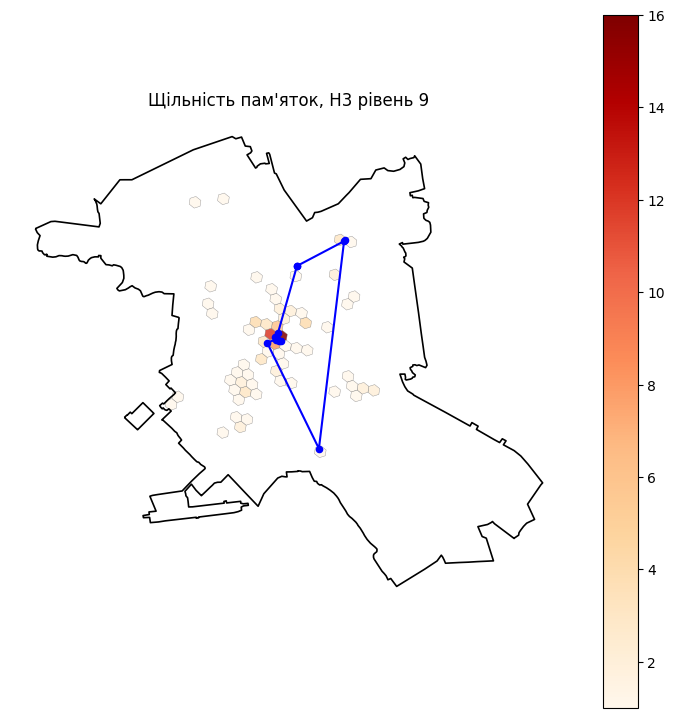

комірок з кандидатами: 61
максимум у комірці   : 16


In [67]:
import h3
from shapely.geometry import Polygon
from shapely.geometry import LineString

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

pts_c = cand.to_crs(32635).geometry.representative_point().to_crs(4326)

cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in pts_c]

dens = cand['h3'].value_counts().rename_axis('h3').reset_index(name='n')
assert dens['n'].sum() == len(cand), 'сума по комірках не збігається з кандидатами'

def cell_poly(c):
    return Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)])

hexes = gpd.GeoDataFrame(dens, geometry=[cell_poly(c) for c in dens['h3']], crs='EPSG:4326')

t_nn = nearest_neighbour(D10)
t_2o = two_opt(D10, t_nn)
print('найближчий сусід :', round(tour_length(D10, t_nn), 1), 'м')
print('після 2-opt      :', round(tour_length(D10, t_2o), 1), 'м')

route_pts = pts10.geometry.iloc[t_2o]
route_line = LineString([(p.x, p.y) for p in route_pts])

# 6. Карта
fig, ax = plt.subplots(figsize=(9, 9))
hexes.plot(ax=ax, column='n', cmap='OrRd', legend=True,
           edgecolor='grey', linewidth=0.3, alpha=0.85)
gpd.GeoSeries([poly], crs='EPSG:4326').boundary.plot(ax=ax, color='black', linewidth=1.2)
gpd.GeoSeries([route_line], crs='EPSG:4326').plot(ax=ax, color='blue', linewidth=1.5)
gpd.GeoSeries(route_pts, crs='EPSG:4326').plot(ax=ax, color='blue', markersize=20)
ax.set_title('Щільність пам\'яток, H3 рівень %d' % H3_RES)
ax.set_axis_off()
plt.show()

print('комірок з кандидатами:', len(dens))
print('максимум у комірці   :', int(dens['n'].max()))

Для 11 найкращих об'єктів маршрут будувався за дорожніми віддалями пішохідного графа. Метод найближчого сусіда дав маршрут довжиною 18 510,7 м. Після покращення 2-opt довжина зменшилася до 17 885,1 м, тобто на 625,6 м, або приблизно на 3,4 %. Обидва результати є евристичними: гарантії оптимальності немає, і 2-opt може зупинитися в локальному мінімумі.

Щільність пам'яток на сітці H3 рівня 9 (середнє ребро 201 м) показує 61 комірку з кандидатами. Найщільніша комірка містить 16 кандидатів.

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [68]:
# ----- ВАШ КОД -----
route_m = pts10.geometry.iloc[t_2o].to_crs(32635)
route_gdf = gpd.GeoDataFrame({'name': pts10['name'].iloc[t_2o].values,
                              'порядок': range(len(t_2o))},
                             geometry=route_m.values, crs=32635)

am_m = amenities.to_crs(32635)
am_m = gpd.GeoDataFrame({'заклад': am_m['name'].values if 'name' in am_m else None,
                         'тип': am_m['amenity'].values if 'amenity' in am_m else None},
                        geometry=am_m.geometry.values, crs=32635)
am_m = am_m[am_m.geometry.notna()]

joined = gpd.sjoin_nearest(route_gdf, am_m, how='left', distance_col='відстань_м')

table = joined[['name', 'порядок', 'заклад', 'тип', 'відстань_м']] \
    .sort_values('порядок').reset_index(drop=True)
table['відстань_м'] = table['відстань_м'].round(1)
display(table)

,name,порядок,заклад,тип,відстань_м
0,СТАРТ: Суми,0,<NA>,cafe,44.9
1,Садиба Линтварьових,1,<NA>,toilets,427.7
2,Меморіальний будинок-музей А. П. Чехова,2,<NA>,toilets,435.6
3,Садиба графині Параскеви Штеричевої,3,Медуниця,cafe,1388.5
4,Садиба Суханових-Сумовських,4,New York Street Pizza,restaurant,53.2
5,Сумський обласний краєзнавчий музей,5,Verde By La Spezia,restaurant,26.2
6,Сумський обласний художній музей ім. Н.Онацького,6,Verde By La Spezia,restaurant,138.0
7,Кожедубу І. М.,7,Vecera,restaurant,72.8
8,Альтанка,8,Gusto,restaurant,77.2
9,Пам'ятник Івану Герасимовичу Харитоненку,9,Terem,cafe,24.2


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [69]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

# ----- ВАШ КОД: folium.Map(..., tiles=BASEMAP), дві PolyLine, маркери з номерами -----
try:
    BASEMAP
except NameError:
    BASEMAP = 'OpenStreetMap'

pts_ll = pts10.geometry.to_crs(4326)
tour_pts = pts_ll.iloc[t_2o]

road_xy = route_coords(t_2o, ids10)

straight_xy = [(p.y, p.x) for p in tour_pts]

center = [np.mean([p[0] for p in straight_xy]), np.mean([p[1] for p in straight_xy])]

fmap = folium.Map(location=center, zoom_start=14, tiles=BASEMAP)

folium.PolyLine(road_xy, color='blue', weight=4, opacity=0.8,
                tooltip='маршрут по ребрах графа').add_to(fmap)

folium.PolyLine(straight_xy, color='red', weight=2, dash_array='6,6',
                tooltip='прямі відрізки між точками').add_to(fmap)

for k, (idx, p) in enumerate(zip(t_2o, tour_pts)):
    if k == len(t_2o) - 1:
        break
    folium.Marker(
        location=(p.y, p.x),
        tooltip=str(pts10['name'].iloc[idx]),
        popup=f"{k}. {pts10['name'].iloc[idx]}",
        icon=folium.DivIcon(html=(
            '<div style="font-size:12pt;font-weight:bold;background:white;'
            'border:2px solid #333;border-radius:50%%;width:24px;height:24px;'
            'line-height:24px;text-align:center">%d</div>' % k)),
    ).add_to(fmap)

folium.LayerControl().add_to(fmap)
fmap.save('lr5_маршрут.html')
print('збережено: lr5_маршрут.html')

збережено: lr5_маршрут.html


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [70]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.0 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [72]:
REPORT = '''
1. Було відкинуто 23 об'єкти, що не відповідали фільтру, та 48 об'єктів без назв. Фільтр варто пояснити замовнику, оскільки безіменні меморіали також можуть бути пам'ятками.
2. У рейтингу використано сигнали: Wikipedia/Wikidata (0,35), мовні назви (0,25), тип туризму (0,20), історичний тег (0,10) та площа (0,10).
3. У двох рейтингах збіглося 5 об'єктів із 10. Це показує, що поняття "найкращі" залежить від обраного критерію.
4. Коефіцієнт обходу становить 1,16. Це трохи нижче типового діапазону 1,2–1,6. Можливе пояснення - це компактність центру міста.
5. Найближчий сусід гірший за точний розв'язок на 3,56%. Це показує, що простий жадібний алгоритм може давати результат, близький до оптимального, але не найкращий.
6. Точний розв'язок для 30 точок недоступний через обмеження пам'яті: таблиця Held–Karp потребує приблизно 257,7 ГБ.
7. Виявлено 5 пар близьких об'єктів, зокрема дублікати однієї садиби з різним написанням назви. Також були злиплі точки та 48 безіменних об'єктів, які відкинули під час фільтрації.

Декларація про використання ШІ:
Використовував Claude AI для того щоб пофіксити завантаження даних із OpenStreetMap, також для вирішення завдань які слідували після цього, код перевіряв.
'''
print(REPORT)


1. Було відкинуто 23 об'єкти, що не відповідали фільтру, та 48 об'єктів без назв. Фільтр варто пояснити замовнику, оскільки безіменні меморіали також можуть бути пам'ятками.
2. У рейтингу використано сигнали: Wikipedia/Wikidata (0,35), мовні назви (0,25), тип туризму (0,20), історичний тег (0,10) та площа (0,10).
3. У двох рейтингах збіглося 5 об'єктів із 10. Це показує, що поняття "найкращі" залежить від обраного критерію.
4. Коефіцієнт обходу становить 1,16. Це трохи нижче типового діапазону 1,2–1,6. Можливе пояснення - це компактність центру міста.
5. Найближчий сусід гірший за точний розв'язок на 3,56%. Це показує, що простий жадібний алгоритм може давати результат, близький до оптимального, але не найкращий.
6. Точний розв'язок для 30 точок недоступний через обмеження пам'яті: таблиця Held–Karp потребує приблизно 257,7 ГБ.
7. Виявлено 5 пар близьких об'єктів, зокрема дублікати однієї садиби з різним написанням назви. Також були злиплі точки та 48 безіменних об'єктів, які відкинул